# Predicting in-hospital death from the first 24 hours in the ICU
### Hands-on Machine Learning — final project (M1 Computer Science, Artificial Intelligence)

**Group members:** [Member 1] · [Member 2] · [Member 3]

**Course:** Hands-on Machine Learning — Marc Evrard (lectures), Yue Ma and Quentin Le Tellier (practical works)

**Data:** WiDS Datathon 2020 — <https://www.kaggle.com/competitions/widsdatathon2020/data>
(also on PhysioNet: <https://physionet.org/content/widsdatathon2020/1.0.0/>). The data is **not** included with this notebook.

---

**How to run.**
1. Download `training_v2.csv`, `unlabeled.csv` (only its `hospital_id` column is read, in Section 2.6) and `WiDS Datathon 2020 Dictionary.csv` from the Kaggle link (requires accepting the competition rules) into `data/raw/`.
2. Keep the helper module `wids_utils.py` next to this notebook (it contains the cleaning, model, metric and plotting functions).
3. Python 3.12 with `pandas`, `scikit-learn`, `lightgbm`, `shap`, `matplotlib`, `seaborn` (exact versions are printed below). A full run takes about 10–15 minutes on a laptop.

**Contents**
1. Introduction — task, clinical motivation, metrics, state of the art and our angle
2. Preprocessing — exploration, leakage checks, cleaning, encoding, train/test split
3. Training — baseline, logistic regression, random forest, LightGBM, and four controlled experiments
4. Evaluation — unseen-hospital test set, threshold, calibration, APACHE comparison, SHAP, errors and subgroups
5. Conclusion

# 1. Introduction

## 1.1 The task in our own words
When a patient arrives in an intensive care unit (ICU), the team records vital signs, lab results, the reason for admission and a few chronic conditions. Our task is to use **only what is known after the first 24 hours of the ICU stay** to estimate the probability that the patient will **die before leaving the hospital** (`hospital_death` = 1).

This is a **binary classification** problem on **tabular data**. The target is hard to obtain (we must wait for the end of the hospital stay) while the features are routine measurements, which is exactly the setting where a predictive model is useful.

## 1.2 Why it matters
* ICU beds and staff are scarce. An early, reliable risk estimate helps decide who needs closer monitoring, earlier escalation, or a conversation with the family about goals of care.
* Hospitals already use **severity scores** such as **APACHE IVa**, which are computed with a fixed formula from the same first-day data. The WiDS 2020 data come from the MIT **GOSSIS** initiative, whose goal is precisely to build an *open* and *global* alternative to these scores. A useful model therefore has to (a) be at least as good as APACHE and (b) **work in hospitals it has never seen**.
* A model used for patient care must produce **trustworthy probabilities** (calibration) and a **clear alert rule** (threshold), not just a high leaderboard score.

## 1.3 Data
WiDS Datathon 2020 (Kaggle, data from the GOSSIS consortium). The labelled file `training_v2.csv` contains one row per ICU stay with demographics, admission context, the APACHE covariates, first-hour (`h1_`) and first-day (`d1_`) vitals and labs, comorbidities, and the APACHE IVa predictions. Exact sizes are measured in Section 2.

## 1.4 Target and evaluation metrics
Only about 9% of patients die, so **accuracy is misleading**: predicting "survives" for everybody already gives ~91% accuracy and is clinically useless. We therefore use:

| Metric | What it answers | Why we use it |
|---|---|---|
| **ROC-AUC** | Probability that a random death is ranked above a random survivor | Threshold-free; the official Kaggle metric, so we can compare with the leaderboard |
| **PR-AUC** (average precision) | Precision averaged over all recall levels | Focuses on the rare positive class; chance level = prevalence (~0.09), not 0.5 |
| **Recall** (sensitivity) at our threshold | Share of deaths that trigger an alert | Our clinical goal: miss as few high-risk patients as possible |
| **Precision**, **F1**, **alert rate** | How many alerts are correct, and how many patients are flagged | The cost side of the alert rule (alarm fatigue) |
| **Brier score** + calibration curve | Are predicted probabilities numerically correct? | A "30% risk" must mean 30% of such patients die if clinicians read the number |
| **Net benefit** (decision curve) | Is using the model better than "alert everyone" / "alert no one"? | Combines benefit and cost of the decision in one clinically interpretable number |

## 1.5 State of the art

The competition ran in January–February 2020 and attracted 951 teams. Scores are ROC-AUC on Kaggle's private test set (about 50% of the 39,308 unlabeled stays), whose labels were never released. All numbers below were read from the cited pages; where a figure was not available, we say so.

| Source | Reported score | Validation used | Main methods | APACHE predictions |
|---|---|---|---|---|
| [1st — Women Power](https://www.kaggle.com/competitions/widsdatathon2020/writeups/women-power-1st-place-approach) ([paper, IEEE 2021](https://ieeexplore.ieee.org/abstract/document/9462159)) | private LB **0.91497** | not grouped (they suspected a hospital-based test split and dropped ID columns after adversarial validation) | Large ensemble (CatBoost, XGBoost, LightGBM, H2O, scikit-learn models, neural nets), 3-layer stacking, pseudo-labelling, test-time augmentation, heavy medical feature engineering | Dropped in most models ("improved validation") |
| [2nd — nullset](https://www.kaggle.com/competitions/widsdatathon2020/writeups/nullset-2nd-place-solution) | public 0.91378 / private **0.91485** | plain K-fold (8 folds) | Ensemble of 26 submissions: LightGBM, XGBoost, logistic regressions; LightGBM-based imputation added as extra columns; group statistics (incl. by `hospital_id`); min/max cleaning | Used (ratio feature) |
| [3rd — Prevision.io](https://www.kaggle.com/competitions/widsdatathon2020/writeups/prevision-io-3rd-place-solution) | private **0.91445** | repeated stratified K-fold | Blend of 2 LightGBM + 1 neural net, pseudo-labelling, diagnosis-group feature | Dropped (also dropped IDs, gender, ethnicity) |
| [6th — Dihydrogen Oxide](https://www.kaggle.com/competitions/widsdatathon2020/writeups/dihydrogen-oxide-6th-place-solution) | private 0.91395 | **5-fold grouped by hospital**, "because most of the hospitals in the test set were not in the training set" | Stacking of 2 XGBoost + 1 LightGBM; delta and diagnosis-average features; min/max flipping | Dropped |
| [7th — Polo5](https://www.kaggle.com/competitions/widsdatathon2020/writeups/polo5-7th-place-solution) | private 0.91348 | repeated stratified K-fold (5×10) | Single LightGBM, frequency encoding, group statistics | Dropped after adversarial validation |
| [14th — u++ & mtmt](https://www.kaggle.com/competitions/widsdatathon2020/writeups/u-mtmt-14th-place-approach-summary) | private 0.91271; best single LightGBM CV 0.9097 | not stated | Ridge stacking of 55–73 models, Optuna, pseudo-labelling, focal loss | Imputed |
| [Source Allies blog (645th)](https://www.sourceallies.com/2020/04/sa-takes-on-wids/) | private 0.90081 | not stated | LightGBM | not stated |
| [Ren, Zhao & Zhang (2022), *Comput. Math. Methods Med.*](https://doi.org/10.1155/2022/3938492) | AUC 0.879 (with severity scores) vs 0.862 (without) | not available in the abstract | Stacked ensemble, SHAP | Compared with / without |
| [Caires Silveira et al. (2022), *World J. Crit. Care Med.*](https://doi.org/10.5492/wjccm.v11.i5.317) | AUC 0.85 (test n = 218) | 80/20 random split of a 1,087-patient subset, 50 variables | Random forest | not stated |
| [Hassan et al. (2025), *IJACSA* 16(2)](https://thesai.org/Publications/ViewPaper?Volume=16&Issue=2&Code=IJACSA&SerialNo=75) | numbers not available in the abstract | not available | Several classifiers + explainable AI; random forest best | not available |

**What we learn from the SOTA**
* The leaderboard is extremely tight: the top 3 are within 0.0005 AUC and the 50th team scored 0.91013, only 0.005 below the winner ([leaderboard](https://www.kaggle.com/competitions/widsdatathon2020/leaderboard)). Gains at the top came from large ensembles, pseudo-labelling and test-time tricks.
* Several top teams **dropped the APACHE predictions** and the hospital/ICU identifiers, and two of them cleaned inverted min/max values — we check these points ourselves.
* None of the write-ups reports **calibration, a decision threshold, subgroup performance or a comparison with APACHE on the same patients**, i.e. what a clinician would need before using the model.
* Our own test score is **not directly comparable** with the leaderboard: Kaggle's test labels are not public, so we evaluate on our own held-out hospitals.

## 1.6 Our angle: *"Would this model be trustworthy in a hospital it has never seen?"*
We deliberately do **not** try to win the leaderboard with a 50-model stack. Instead we ask the question a hospital would ask before deploying such a model, and design each step to answer it:

1. **Leakage-aware validation by hospital.** We measured that the Kaggle test set contains mostly hospitals absent from the training data (Section 2.6). We therefore hold out a test set of **entire unseen hospitals** and use **grouped cross-validation**, and we **quantify** how optimistic a random split would have been.
2. **Head-to-head with the clinical standard.** APACHE IVa is excluded from our features (to stay independent from it) and kept as a **benchmark**, compared on the same patients with bootstrap confidence intervals. We also show the result *with* APACHE as a feature.
3. **"What did the doctors measure?"** An experiment showing how much the *pattern of missing values* alone predicts death.
4. **A clinically motivated decision rule**: a threshold chosen to catch 80% of deaths, its cost in alerts, calibration, and a decision curve.
5. **Explanation and error analysis** with SHAP, per-subgroup (age, sex, ethnicity, ICU type) and per-hospital performance.

We keep the models simple (one model per family, standard libraries) so that every result can be explained.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import lightgbm
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

import wids_utils as wu  # our helper module (same folder as this notebook)

DATA_DIR = "data/raw"
RANDOM_STATE = wu.RANDOM_STATE  # 42, used for every split and model
TARGET_RECALL = 0.80            # clinical goal: catch at least 80% of deaths (Section 4.1)

np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"lightgbm {lightgbm.__version__} | shap {shap.__version__}")

pandas 3.0.6 | scikit-learn 1.9.1 | lightgbm 4.7.0 | shap 0.53.0


# 2. Preprocessing

## 2.1 First look at the data

In [2]:
raw, dictionary = wu.load_raw_data(DATA_DIR)
print(f"{raw.shape[0]:,} ICU stays x {raw.shape[1]} columns")
print(raw.dtypes.astype(str).replace({"str": "text", "object": "text"}).value_counts().to_string())

91,713 ICU stays x 186 columns
float64    170
int64        8
text         8


The data dictionary assigns every column to a category. This gives a readable overview of the ~180 features:

In [3]:
category_of = dictionary.set_index("Variable Name")["Category"]
feature_groups = category_of.reindex(raw.columns).fillna("not in dictionary")
print(feature_groups.value_counts().to_string())
print("\nIn the dictionary but not in the data:",
      sorted(set(category_of.index) - set(raw.columns)))

Category
labs                  60
vitals                52
APACHE covariate      28
labs blood gas        16
demographic           15
APACHE comorbidity     8
identifier             3
APACHE prediction      2
APACHE grouping        2

In the dictionary but not in the data: ['icu_admit_type', 'pred']


* `h1_*` = min/max during the **first hour**, `d1_*` = min/max during the **first day**, `*_apache` = the value used by the APACHE score (worst value of the first day).
* Most features are numeric; 8 are text categories (sex, ethnicity, admission source, ICU type, diagnosis body system...).

## 2.2 Target balance

In [4]:
deaths = raw[wu.TARGET].sum()
print(f"Deaths: {deaths:,} / {len(raw):,} = {deaths / len(raw):.2%}   |   survivors: {len(raw) - deaths:,}")
print(f"Accuracy of always predicting 'survives': {1 - deaths / len(raw):.2%}")

Deaths: 7,915 / 91,713 = 8.63%   |   survivors: 83,798
Accuracy of always predicting 'survives': 91.37%


**Observation.** 8.63% of stays end in death (7,915 / 91,713). A model that always answers "survives" reaches 91.37% accuracy while detecting no death at all, which is why accuracy is not one of our metrics. We keep the natural class balance in training (no over/under-sampling) and handle the imbalance with the choice of metrics and decision threshold (Sections 3.10 and 4.1).

## 2.3 Missing values
Not every lab test is ordered for every patient, so missingness is expected. We look at it per column and per patient.

In [5]:
missing_share = raw.isna().mean().sort_values(ascending=False)
print(f"Columns with any missing value: {(missing_share > 0).sum()} / {raw.shape[1]}")
for limit in (0.5, 0.8, 0.9):
    print(f"  more than {limit:.0%} missing: {(missing_share > limit).sum()} columns")
print(f"Rows with at least one missing value: {raw.isna().any(axis=1).mean():.2%}")
print("\nMost incomplete columns:")
print(missing_share.head(8).round(3).to_string())

Columns with any missing value: 175 / 186
  more than 50% missing: 74 columns
  more than 80% missing: 34 columns
  more than 90% missing: 6 columns
Rows with at least one missing value: 99.97%

Most incomplete columns:
h1_bilirubin_min        0.923
h1_bilirubin_max        0.923
h1_lactate_max          0.920
h1_lactate_min          0.920
h1_albumin_max          0.914
h1_albumin_min          0.914
h1_pao2fio2ratio_min    0.874
h1_pao2fio2ratio_max    0.874


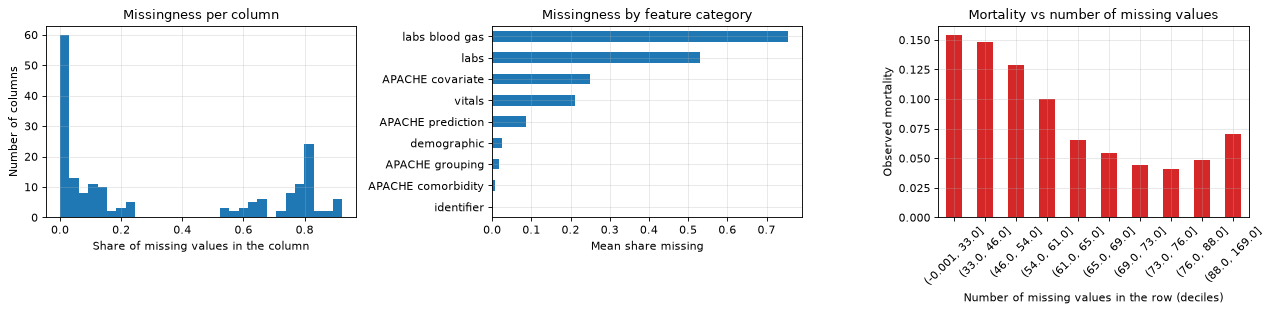

In [6]:
n_missing_per_row = raw.isna().sum(axis=1)
missing_decile = pd.qcut(n_missing_per_row, 10, duplicates="drop")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
missing_share.plot.hist(bins=30, ax=axes[0], color="tab:blue")
axes[0].set(xlabel="Share of missing values in the column", ylabel="Number of columns",
            title="Missingness per column")

by_group = missing_share.groupby(feature_groups).mean().sort_values()
by_group.plot.barh(ax=axes[1], color="tab:blue")
axes[1].set(xlabel="Mean share missing", ylabel="", title="Missingness by feature category")

raw.groupby(missing_decile, observed=True)[wu.TARGET].mean().plot.bar(ax=axes[2], color="tab:red")
axes[2].set(xlabel="Number of missing values in the row (deciles)", ylabel="Observed mortality",
            title="Mortality vs number of missing values")
axes[2].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

**Observations.**
* 175 of 186 columns have missing values, 74 columns are more than 50% missing and 34 more than 80%. Practically **every row (99.97%) has at least one missing value**, so dropping incomplete rows is impossible.
* The most incomplete columns are **first-hour labs** (`h1_bilirubin`, `h1_lactate`, `h1_albumin`: ~92% missing) and **blood gases**: these tests are only ordered for some patients, and rarely within the first hour.
* **Missingness is informative** (right plot): patients with the *fewest* missing values have the *highest* mortality (~15%), and mortality falls to ~4% for patients with many missing values. Clinicians order more tests when they are worried. The data are therefore not "missing completely at random".

**Consequences for preprocessing.** We do not delete columns just because they are very incomplete, and we never use an imputation that hides the fact that a value was missing: LightGBM and the random forest handle missing values natively, and logistic regression receives a 0/1 "was missing" indicator for each imputed column. Section 3.9 measures how much signal the missingness pattern contains.

## 2.4 Distributions and outliers
We compare a few clinically important variables between survivors and non-survivors, and check whether extreme values look like errors.

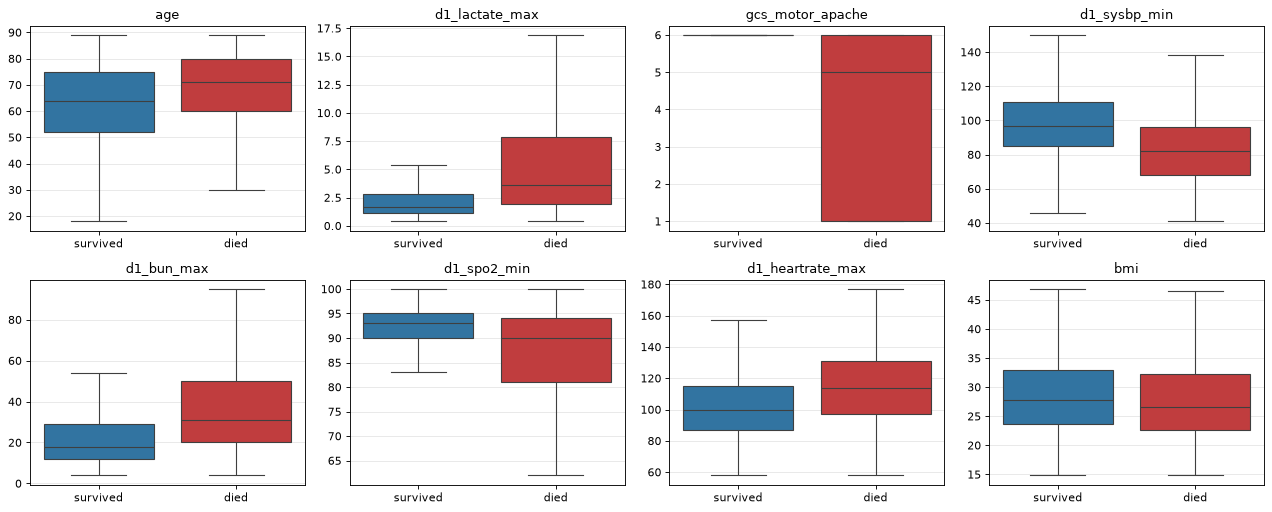

In [7]:
key_features = ["age", "d1_lactate_max", "gcs_motor_apache", "d1_sysbp_min",
                "d1_bun_max", "d1_spo2_min", "d1_heartrate_max", "bmi"]
outcome_labelled = raw[key_features].assign(outcome=raw[wu.TARGET].map({0: "survived", 1: "died"}))
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, feature in zip(axes.ravel(), key_features):
    sns.boxplot(data=outcome_labelled, x="outcome", y=feature, ax=ax, showfliers=False,
                hue="outcome", palette={"survived": "tab:blue", "died": "tab:red"})
    ax.set(xlabel="", ylabel="", title=feature)
fig.tight_layout()
plt.show()

In [8]:
# Are the extremes clipped? Share of values sitting exactly on the column minimum / maximum.
vitals = ["d1_heartrate_max", "d1_heartrate_min", "d1_temp_min", "d1_sysbp_min", "d1_resprate_max", "bmi"]
extremes = pd.DataFrame({
    "min": raw[vitals].min(), "max": raw[vitals].max(),
    "% at min": (raw[vitals] == raw[vitals].min()).mean() * 100,
    "% at max": (raw[vitals] == raw[vitals].max()).mean() * 100,
})
print(extremes.round(2).to_string())
print(f"\nAge range: {raw.age.min():.0f}-{raw.age.max():.0f}, "
      f"share aged exactly {raw.age.max():.0f}: {(raw.age == raw.age.max()).mean():.2%}")
print(f"Negative pre-ICU length of stay: {(raw.pre_icu_los_days < 0).sum()} rows")
print(f"Inverted min/max pairs (min > max): {wu.count_inverted_min_max(raw)}")
print(f"APACHE predictions equal to -1: {(raw[wu.APACHE_PREDICTIONS] == -1).sum().to_dict()}")

                    min     max  % at min  % at max
d1_heartrate_max  58.00  177.00      0.68      0.48
d1_heartrate_min   0.00  175.00      0.65      0.00
d1_temp_min       31.89   37.80      0.57      0.40
d1_sysbp_min      41.00  160.00      0.55      0.48
d1_resprate_max   14.00   92.00      0.87      0.53
bmi               14.84   67.81      0.48      0.46

Age range: 16-89, share aged exactly 89: 1.04%
Negative pre-ICU length of stay: 778 rows
Inverted min/max pairs (min > max): 1126
APACHE predictions equal to -1: {'apache_4a_hospital_death_prob': 2371, 'apache_4a_icu_death_prob': 2230}


**Observations.**
* The boxplots match clinical intuition: patients who died are older (median ≈ 71 vs 64), have higher lactate (a marker of poor tissue perfusion), lower motor GCS (reduced consciousness), lower minimum blood pressure and oxygen saturation, higher urea (BUN, kidney function) and higher heart rate. BMI barely differs.
* Extreme values are **physiologically plausible** for ICU patients (e.g. a first-day minimum heart rate of 0 can be a cardiac arrest) and about 0.5% of the values sit exactly on each column's minimum or maximum: the provider has **already clipped** extreme values to fixed bounds. Age is capped at 89 (1.04% of patients), a usual de-identification rule. We therefore do not remove more "outliers": that would delete exactly the sickest patients.
* Real data-quality problems that we do fix in 2.7: 778 negative pre-ICU stays, 1,126 inverted min/max pairs, and the `-1` code in the APACHE predictions (2,371 and 2,230 rows).

## 2.5 Categorical variables and correlations

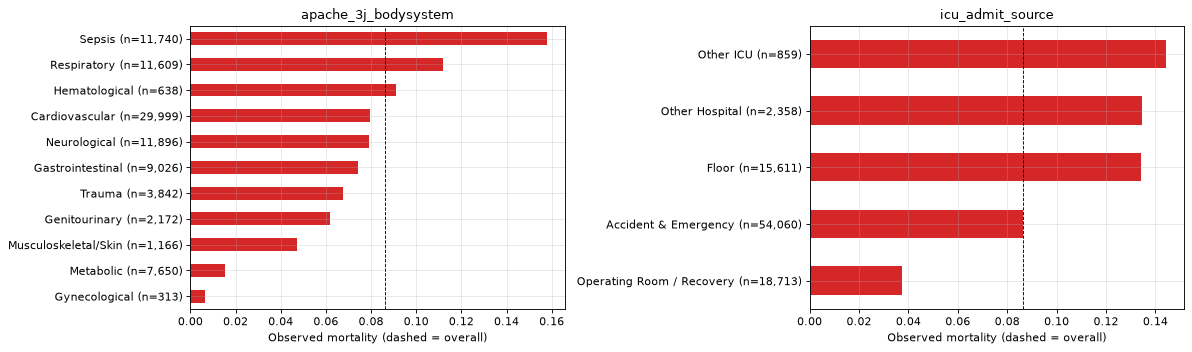

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, column in zip(axes, ["apache_3j_bodysystem", "icu_admit_source"]):
    summary = raw.groupby(column)[wu.TARGET].agg(["mean", "size"]).sort_values("mean")
    summary.index = [f"{name} (n={size:,})" for name, size in summary["size"].items()]
    summary["mean"].plot.barh(ax=ax, color="tab:red")
    ax.axvline(raw[wu.TARGET].mean(), color="k", ls="--", lw=0.8)
    ax.set(xlabel="Observed mortality (dashed = overall)", ylabel="", title=column)
fig.tight_layout()
plt.show()

**How strongly is each single feature linked to the target?** For a numeric feature, the ROC-AUC obtained by using the raw value as a score (oriented so that it is ≥ 0.5) is a simple, scale-free measure of association that also captures monotonic non-linear relations. This tells us whether the task is "too easy" (one feature giving the answer).

In [10]:
numeric_columns = raw.select_dtypes("number").columns.drop([wu.TARGET] + wu.ID_COLUMNS)
univariate_auc = {}
for column in numeric_columns:
    known = raw[column].notna() & (raw[column] >= 0 if column in wu.APACHE_PREDICTIONS else True)
    if raw.loc[known, column].nunique() > 1:
        auc = roc_auc_score(raw.loc[known, wu.TARGET], raw.loc[known, column])
        univariate_auc[column] = max(auc, 1 - auc)
univariate_auc = pd.Series(univariate_auc).sort_values(ascending=False)
print(univariate_auc.head(12).round(3).to_string())

apache_4a_hospital_death_prob    0.863
apache_4a_icu_death_prob         0.858
d1_lactate_max                   0.736
d1_lactate_min                   0.731
h1_lactate_min                   0.712
h1_lactate_max                   0.710
d1_sysbp_min                     0.705
d1_sysbp_noninvasive_min         0.705
gcs_verbal_apache                0.705
d1_bun_max                       0.703
bun_apache                       0.699
ventilated_apache                0.691


Feature pairs with |r| > 0.95: 64
paco2_apache       paco2_for_ph_apache    1.000
d1_inr_min         h1_inr_min             1.000
d1_inr_max         h1_inr_max             1.000
h1_bilirubin_max   h1_bilirubin_min       1.000
h1_albumin_max     h1_albumin_min         1.000
h1_bun_max         h1_bun_min             1.000
h1_creatinine_max  h1_creatinine_min      0.999
h1_platelets_max   h1_platelets_min       0.998


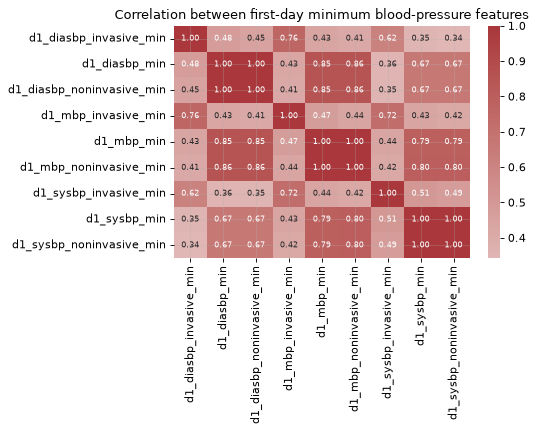

In [11]:
correlations = raw[numeric_columns.drop(wu.APACHE_PREDICTIONS)].corr().abs()
upper = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1))
very_correlated = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print(f"Feature pairs with |r| > 0.95: {len(very_correlated)}")
print(very_correlated.head(8).round(3).to_string())

blood_pressure = [c for c in numeric_columns if c.startswith("d1_") and "bp" in c and "min" in c]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(raw[blood_pressure].corr(), cmap="vlag", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation between first-day minimum blood-pressure features")
fig.tight_layout()
plt.show()

**Observations.**
* The strongest single measured feature (`d1_lactate_max`) reaches a ROC-AUC of only 0.736 on its own. The APACHE IVa predictions, which already combine many variables, reach 0.863. **No single feature gives the answer**, so the task is not trivial; the challenge is to combine many weak, partly missing signals.
* 64 pairs of numeric features have |r| > 0.95. Many are `h1_*_min` / `h1_*_max` pairs that are identical when a lab was measured only once in the first hour; others are the same quantity measured in two ways (invasive vs non-invasive blood pressure, `paco2_apache` vs `paco2_for_ph_apache`).
* We keep these redundant features: tree models are not harmed by redundancy for prediction, and logistic regression uses L2 regularisation, which stabilises correlated coefficients. The price is on interpretation: when two features carry the same information, their importance is **shared** between them (we keep this in mind when reading SHAP values).

## 2.6 Identifiers and leakage checks
Leakage = information that would not be available at prediction time, or that makes the validation unrealistically easy. We check four sources.

In [12]:
print(pd.Series({c: raw[c].nunique() for c in wu.ID_COLUMNS}, name="unique values").to_string())
print(f"\nEvery patient_id appears once: {raw.patient_id.is_unique}")

stays_per_hospital = raw.groupby("hospital_id").size()
mortality_per_hospital = raw.groupby("hospital_id")[wu.TARGET].mean()
print(f"Stays per hospital: median {stays_per_hospital.median():.0f}, "
      f"min {stays_per_hospital.min()}, max {stays_per_hospital.max()}")
large = stays_per_hospital >= 100
print(f"Mortality across hospitals with >= 100 stays: "
      f"{mortality_per_hospital[large].min():.1%} to {mortality_per_hospital[large].max():.1%}")

# Only the hospital column of the unlabeled (Kaggle test) file is read.
test_hospitals = set(pd.read_csv(f"{DATA_DIR}/unlabeled.csv", usecols=["hospital_id"]).hospital_id)
shared = test_hospitals & set(raw.hospital_id)
print(f"\nKaggle test file: {len(test_hospitals)} hospitals, only {len(shared)} also present in training")

encounter_id    91713
patient_id      91713
hospital_id       147
icu_id            241

Every patient_id appears once: True
Stays per hospital: median 323, min 2, max 4333
Mortality across hospitals with >= 100 stays: 0.0% to 29.1%



Kaggle test file: 66 hospitals, only 9 also present in training


In [13]:
apache = raw[wu.APACHE_PREDICTIONS].where(raw[wu.APACHE_PREDICTIONS] >= 0)
has_apache = apache.notna().all(axis=1)
print(f"Stays with a valid APACHE IVa prediction: {has_apache.mean():.1%}")
for column in wu.APACHE_PREDICTIONS:
    auc = roc_auc_score(raw.loc[has_apache, wu.TARGET], apache.loc[has_apache, column])
    print(f"  ROC-AUC of {column} used directly as a score: {auc:.4f}")

Stays with a valid APACHE IVa prediction: 88.4%
  ROC-AUC of apache_4a_hospital_death_prob used directly as a score: 0.8633
  ROC-AUC of apache_4a_icu_death_prob used directly as a score: 0.8585


**Leakage decisions**

| Source | Finding | Decision |
|---|---|---|
| `encounter_id`, `patient_id` | Unique per row (no patient appears twice) | Dropped: pure identifiers. Grouping by patient is unnecessary since no patient repeats. |
| `hospital_id`, `icu_id` | 147 hospitals with very different mortality; the Kaggle test file is mostly **other** hospitals | Not used as features. Used as **groups** for splitting so that validation mimics a new hospital. |
| `apache_4a_*_death_prob` | Output of an existing clinical model computed from the same first-day data | **Excluded from our main model** and kept as a **benchmark**. We also train a variant that includes them (Section 3.8). |
| Timing | Per the dictionary, all features are collected during the first 24 h (or before ICU admission); none describes events after the outcome | Kept. |

We also note one inconsistency: `readmission_status` is 0 for everybody although `icu_stay_type` contains "readmit" stays, so `readmission_status` carries no information and is dropped.

## 2.7 Cleaning
All cleaning steps are in `wu.clean_data` (module `wids_utils.py`). Each step is a decision we can justify:

| Step | Why |
|---|---|
| Drop `readmission_status` | Constant (always 0) |
| Merge "Undefined Diagnoses" / "Undefined diagnoses" | Same category spelled twice |
| APACHE predictions `-1` → missing | `-1` is a code for "could not be computed", not a probability |
| Negative `pre_icu_los_days` → missing | A negative duration is impossible |
| Swap inverted min/max | A minimum larger than the maximum is a recording error; swapping keeps both values (also done by the 6th-place team) |
| Diagnosis codes → categories | `apache_3j_diagnosis` = 502.01 is a code, not a quantity. We keep its integer part (112 diagnosis groups) and treat both diagnosis columns as categories |

We do **not** clip outliers further, since Section 2.4 shows that the provider already clipped values to plausible ranges, and tree models are insensitive to extreme values.

In [14]:
df = wu.clean_data(raw)
print(f"Inverted min/max pairs after cleaning: {wu.count_inverted_min_max(df)}")
print(f"Diagnosis groups: {df.apache_3j_diagnosis.nunique()} (APACHE III), "
      f"{df.apache_2_diagnosis.nunique()} (APACHE II)")
print(f"Cleaned table: {df.shape[0]:,} rows x {df.shape[1]} columns")

Inverted min/max pairs after cleaning: 0
Diagnosis groups: 112 (APACHE III), 44 (APACHE II)
Cleaned table: 91,713 rows x 185 columns


## 2.8 Features, encoding and imputation
`wu.build_features` removes the identifiers and the target (and the APACHE predictions unless asked), adds one engineered feature, and marks text columns as categories.

* **`n_missing_values`** = number of missing numeric measurements for the patient. Section 2.3 showed that mortality changes with the number of missing values; this count summarises *how intensively the patient was monitored*.

Each model family needs a different preprocessing. Everything that learns from data (medians, scaling, encoders) is **inside a scikit-learn pipeline**, so it is re-fitted on the training folds only and never sees validation or test data.

| Model | Missing numeric values | Categories | Scaling |
|---|---|---|---|
| Logistic regression | Median imputation **+ a 0/1 "was missing" indicator** per column (so the model can still use missingness) | One-hot (categories with < 50 patients grouped as "infrequent") | Standardisation (needed so the L2 penalty treats all features equally) |
| Random forest | Native support in scikit-learn ≥ 1.4 (the split learns which side missing values go to) | Ordinal codes (trees only need an order to split on) | Not needed |
| LightGBM | Native support (same idea) | Native categorical splits | Not needed |

In [15]:
X, y, groups = wu.build_features(df)
X_with_apache, _, _ = wu.build_features(df, include_apache=True)
print(f"Feature matrix: {X.shape[0]:,} x {X.shape[1]}  "
      f"({len(wu.categorical_columns(X))} categorical, {X.shape[1] - len(wu.categorical_columns(X))} numeric)")

Feature matrix: 91,713 x 179  (10 categorical, 169 numeric)


## 2.9 Train / test split by hospital
We hold out about 20% of the data as a **final test set made of whole hospitals** that the models never see during training or tuning. `StratifiedGroupKFold` assigns each hospital entirely to one side while keeping the death rate similar on both sides; we use its first fold as the test set. Everything in Section 3 uses only the development set.

In [16]:
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
dev_idx, test_idx = next(outer_split.split(X, y, groups))

X_dev, y_dev, groups_dev = X.iloc[dev_idx], y[dev_idx], groups[dev_idx]
X_test, y_test, groups_test = X.iloc[test_idx], y[test_idx], groups[test_idx]
X_dev_apache, X_test_apache = X_with_apache.iloc[dev_idx], X_with_apache.iloc[test_idx]

split_summary = pd.DataFrame({
    "stays": [len(dev_idx), len(test_idx)],
    "hospitals": [len(set(groups_dev)), len(set(groups_test))],
    "mortality": [y_dev.mean(), y_test.mean()],
}, index=["development", "test"])
print(split_summary.to_string())
print(f"Hospitals in both sets: {len(set(groups_dev) & set(groups_test))}")

             stays  hospitals  mortality
development  73401        113      0.086
test         18312         34      0.087
Hospitals in both sets: 0


# 3. Training

## 3.1 Validation strategy
All model selection is done with **5-fold `StratifiedGroupKFold` on the development set, grouped by hospital**: in each fold, the validation hospitals are absent from the training folds. This reproduces the real use case (a new hospital) and the Kaggle setting (mostly unseen hospitals).

We progress from the simplest to the most flexible model, so that each step has to *earn* its complexity:
1. **Dummy** baseline: predicts the training death rate for everybody → ROC-AUC 0.5 by construction. Any useful model must beat it.
2. **Logistic regression**: linear, fast, interpretable coefficients. Tuned: regularisation strength `C`.
3. **Random forest**: many decorrelated decision trees averaged; captures non-linearities and interactions. Tuned: leaf size and number of features per split.
4. **LightGBM** (gradient boosting): trees added one at a time, each correcting the previous errors; usually the strongest model family on tabular data (and used by all top Kaggle teams).

**Tuning budget.** We use a random search (`RandomizedSearchCV`) with a small number of candidates per model (6 / 4 / 8), scored by ROC-AUC on a **3-fold** grouped split to keep the notebook runtime reasonable. The selected setting of each model is then evaluated with the full **5-fold** grouped CV, which gives the numbers we compare. ROC-AUC is used for tuning because it is the competition metric; PR-AUC is reported alongside.

In [17]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuning_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}     # model name -> per-fold scores
oof_predictions = {}  # model name -> out-of-fold probabilities on the development set


def run_cv(name, model, features=None):
    """Grouped CV of `model`; stores and returns its fold scores."""
    features = X_dev if features is None else features
    oof_predictions[name], cv_results[name] = wu.cross_validated_predictions(
        model, features, y_dev, cv, groups_dev)
    return wu.summarise_folds(cv_results[name])

## 3.2 Dummy baseline

In [18]:
run_cv("Dummy (prior)", DummyClassifier(strategy="prior"))

{'roc_auc': '0.5000 ± 0.0000', 'pr_auc': '0.0862 ± 0.0020'}

## 3.3 Logistic regression

In [19]:
lr_params, lr_search = wu.tune_hyperparameters(
    wu.make_logistic_regression(X_dev),
    {"logisticregression__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]},
    X_dev, y_dev, groups_dev, tuning_cv, n_iter=6, n_jobs=-1)
display(lr_search.head(6))
print("Selected:", lr_params)
logistic_regression = wu.make_logistic_regression(X_dev).set_params(**lr_params)
run_cv("Logistic regression", logistic_regression)

,params,mean_test_score,std_test_score,mean_fit_time
2,{'logisticregression__C': 0.03},0.889,0.004,10.150
3,{'logisticregression__C': 0.1},0.889,0.004,11.289
1,{'logisticregression__C': 0.01},0.889,0.004,8.663
4,{'logisticregression__C': 0.3},0.888,0.004,10.107
5,{'logisticregression__C': 1.0},0.888,0.004,8.153
0,{'logisticregression__C': 0.003},0.887,0.004,7.085


Selected: {'logisticregression__C': 0.03}


{'roc_auc': '0.8902 ± 0.0058', 'pr_auc': '0.5314 ± 0.0126'}

**Observation.** All values of `C` between 0.003 and 1 give almost the same AUC (0.887–0.889 on the 3-fold tuning split): with 73,000 training stays, the amount of regularisation hardly matters. With 5-fold grouped CV, logistic regression reaches **ROC-AUC 0.890** and **PR-AUC 0.531**, already a strong baseline. This suggests that much of the signal is roughly monotonic (the higher the lactate, the higher the risk).

## 3.4 Random forest

In [20]:
rf_params, rf_search = wu.tune_hyperparameters(
    wu.make_random_forest(X_dev),
    {"randomforestclassifier__min_samples_leaf": [3, 10, 30],
     "randomforestclassifier__max_features": ["sqrt", 0.1]},
    X_dev, y_dev, groups_dev, tuning_cv, n_iter=4)
display(rf_search)
print("Selected:", rf_params)
random_forest = wu.make_random_forest(X_dev).set_params(**rf_params)
run_cv("Random forest", random_forest)

,params,mean_test_score,std_test_score,mean_fit_time
1,{'randomforestclassifier__min_samples_leaf': 1...,0.885,0.004,5.620
2,{'randomforestclassifier__min_samples_leaf': 3...,0.884,0.004,6.178
3,{'randomforestclassifier__min_samples_leaf': 3...,0.884,0.004,4.735
0,{'randomforestclassifier__min_samples_leaf': 3...,0.883,0.003,6.518


Selected: {'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 'sqrt'}


{'roc_auc': '0.8868 ± 0.0074', 'pr_auc': '0.5352 ± 0.0135'}

## 3.5 LightGBM

In [21]:
lgbm_params, lgbm_search = wu.tune_hyperparameters(
    wu.make_lightgbm(),
    {"num_leaves": [15, 31, 63],
     "learning_rate": [0.02, 0.05],
     "n_estimators": [300, 600, 1000],
     "min_child_samples": [20, 50, 100],
     "colsample_bytree": [0.3, 0.5, 0.8],
     "reg_lambda": [0.0, 1.0, 10.0]},
    X_dev, y_dev, groups_dev, tuning_cv, n_iter=8)
display(lgbm_search.head(8))
print("Selected:", lgbm_params)
lightgbm_model = wu.make_lightgbm(**lgbm_params)
run_cv("LightGBM", lightgbm_model)

,params,mean_test_score,std_test_score,mean_fit_time
4,"{'reg_lambda': 1.0, 'num_leaves': 31, 'n_estim...",0.906,0.003,7.243
7,"{'reg_lambda': 0.0, 'num_leaves': 15, 'n_estim...",0.906,0.003,4.906
6,"{'reg_lambda': 1.0, 'num_leaves': 31, 'n_estim...",0.906,0.003,4.189
0,"{'reg_lambda': 0.0, 'num_leaves': 63, 'n_estim...",0.903,0.002,12.178
1,"{'reg_lambda': 1.0, 'num_leaves': 15, 'n_estim...",0.903,0.004,8.071
5,"{'reg_lambda': 0.0, 'num_leaves': 63, 'n_estim...",0.903,0.003,6.113
3,"{'reg_lambda': 1.0, 'num_leaves': 63, 'n_estim...",0.903,0.003,13.494
2,"{'reg_lambda': 10.0, 'num_leaves': 63, 'n_esti...",0.900,0.003,23.064


Selected: {'reg_lambda': 1.0, 'num_leaves': 31, 'n_estimators': 600, 'min_child_samples': 50, 'learning_rate': 0.02, 'colsample_bytree': 0.8}


{'roc_auc': '0.9078 ± 0.0049', 'pr_auc': '0.5901 ± 0.0095'}

## 3.6 Cross-validated comparison

In [22]:
def cv_table(names):
    return pd.DataFrame({name: wu.summarise_folds(cv_results[name]) for name in names}).T

cv_table(["Dummy (prior)", "Logistic regression", "Random forest", "LightGBM"])

,roc_auc,pr_auc
Dummy (prior),0.5000 ± 0.0000,0.0862 ± 0.0020
Logistic regression,0.8902 ± 0.0058,0.5314 ± 0.0126
Random forest,0.8868 ± 0.0074,0.5352 ± 0.0135
LightGBM,0.9078 ± 0.0049,0.5901 ± 0.0095


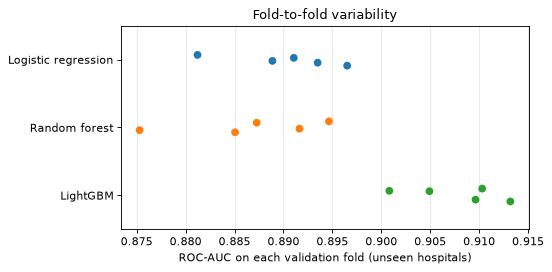

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.5))
fold_auc = pd.DataFrame({name: cv_results[name]["roc_auc"]
                         for name in ["Logistic regression", "Random forest", "LightGBM"]})
sns.stripplot(data=fold_auc, orient="h", size=7, ax=ax)
ax.set(xlabel="ROC-AUC on each validation fold (unseen hospitals)", title="Fold-to-fold variability")
fig.tight_layout()
plt.show()

**Observations.**
* **LightGBM is the best model**: ROC-AUC 0.908 ± 0.005 and PR-AUC 0.590 ± 0.010 across the 5 grouped folds, about +0.018 ROC-AUC and +0.06 PR-AUC above logistic regression. Gradient boosting builds trees sequentially, each one correcting the errors of the previous ones, and captures non-linear effects (e.g. both very low and very high heart rate are dangerous) and interactions that a linear model cannot.
* The random forest (0.887) does **not** beat logistic regression on ROC-AUC (similar PR-AUC). Averaging independent trees reduces variance but does not focus on the hard cases the way boosting does; with our small tuning budget it is the weakest of the three.
* The **fold-to-fold standard deviation (≈ 0.005)** is as large as the spread of the whole top-50 of the Kaggle leaderboard (0.0048). Differences in the third decimal between models or teams are therefore mostly noise; this is why we do not chase them.

## 3.7 Experiment 1 — does a random split overestimate performance?
We evaluate the selected LightGBM again with an ordinary **random** stratified 5-fold split (patients of the same hospital on both sides) and compare it with the grouped split. To make the effect of hospital information explicit, we also add `hospital_id` as a feature: under a random split the model can learn each hospital's death rate and *seem* to benefit from it; under a grouped split, the validation hospitals are unknown so this knowledge cannot help.

In [24]:
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_dev_hospital = X_dev.assign(hospital_id=pd.Categorical(groups_dev))

split_experiment = {("grouped by hospital", "without hospital_id"): wu.summarise_folds(cv_results["LightGBM"])}
for split_name, splitter, split_groups, feature_name, features in [
        ("grouped by hospital", cv, groups_dev, "with hospital_id", X_dev_hospital),
        ("random split", random_cv, None, "without hospital_id", X_dev),
        ("random split", random_cv, None, "with hospital_id", X_dev_hospital)]:
    _, scores = wu.cross_validated_predictions(lightgbm_model, features, y_dev, splitter, split_groups)
    split_experiment[(split_name, feature_name)] = wu.summarise_folds(scores)
pd.DataFrame(split_experiment).T.sort_index()

roc_auc           pr_auc
grouped by hospital with hospital_id     0.9061 ± 0.0051  0.5836 ± 0.0128
                    without hospital_id  0.9078 ± 0.0049  0.5901 ± 0.0095
random split        with hospital_id     0.9078 ± 0.0049  0.6004 ± 0.0182
                    without hospital_id  0.9087 ± 0.0048  0.5947 ± 0.0186

**Observations.**
* Without hospital information, the random split is only slightly more optimistic than the grouped split (ROC-AUC 0.9087 vs 0.9078, PR-AUC 0.595 vs 0.590): the physiological signal **generalises well across hospitals** in this dataset. We report this honestly: the optimism of a random split is real but small here.
* The effect of hospital information is clearer. **Adding `hospital_id` gives the best PR-AUC of all under a random split (0.600), but the worst under a grouped split (0.584).** With a random split, the model can memorise each hospital's death rate, and the validation patients come from the same hospitals, so this looks useful. For a new hospital, it is useless and even harmful. A random split would have encouraged us to keep a feature that hurts in deployment, as happened to Kaggle teams that built hospital-level statistics with plain K-fold.
* This confirms our choice: hospital identifiers are excluded and all model selection is grouped by hospital.

## 3.8 Experiment 2 — APACHE predictions as features
Same LightGBM settings, with the two APACHE IVa probabilities added as features. We also score APACHE IVa alone on the same validation patients (it needs no training).

In [25]:
run_cv("LightGBM + APACHE features", lightgbm_model, X_dev_apache)

dev_apache = X_dev_apache["apache_4a_hospital_death_prob"].to_numpy()
dev_has_apache = ~np.isnan(dev_apache)
print(f"On the {dev_has_apache.sum():,} development stays with an APACHE score (out-of-fold predictions):")
for name, scores in [("APACHE IVa alone", dev_apache),
                     ("LightGBM (no APACHE)", oof_predictions["LightGBM"]),
                     ("LightGBM + APACHE features", oof_predictions["LightGBM + APACHE features"])]:
    print(f"  {name:28s} ROC-AUC {roc_auc_score(y_dev[dev_has_apache], scores[dev_has_apache]):.4f}")
cv_table(["LightGBM", "LightGBM + APACHE features"])

On the 65,578 development stays with an APACHE score (out-of-fold predictions):
  APACHE IVa alone             ROC-AUC 0.8630
  LightGBM (no APACHE)         ROC-AUC 0.9081
  LightGBM + APACHE features   ROC-AUC 0.9062


,roc_auc,pr_auc
LightGBM,0.9078 ± 0.0049,0.5901 ± 0.0095
LightGBM + APACHE features,0.9050 ± 0.0047,0.5875 ± 0.0119


**Observations.**
* Adding the two APACHE IVa probabilities as features does **not** improve LightGBM (ROC-AUC 0.905 vs 0.908). On the 65,578 development stays that have an APACHE score, APACHE alone reaches 0.863 while our model without it reaches 0.908 (out-of-fold).
* Explanation: APACHE IVa is a fixed formula of the same first-day variables (worst vital signs and labs, age, diagnosis, chronic conditions) that are already in our feature set. It brings **no new information**, only a summary the model can rebuild (and better). This agrees with the top Kaggle teams, who dropped these columns.
* **Decision:** our main model does not use the APACHE predictions. It is then independent of the score we want to compare against, and it also works for the 11.6% of patients for whom APACHE could not be computed.

## 3.9 Experiment 3 — what does the *pattern of missing values* tell us?
We train LightGBM on a matrix that contains **only 0/1 indicators of whether each measurement is missing**, with no measured values at all. If this model predicts death well, then *which tests the clinicians decided to order* is itself a strong signal of how sick they judged the patient. This justifies keeping missingness information (native NaN handling, missing indicators) instead of hiding it with plain imputation.

In [26]:
missing_only = wu.missingness_matrix(X_dev)
print(f"Missingness matrix: {missing_only.shape[1]} binary columns")
run_cv("LightGBM on missingness only", wu.make_lightgbm(), missing_only)
cv_table(["Dummy (prior)", "LightGBM on missingness only", "LightGBM"])

Missingness matrix: 168 binary columns


,roc_auc,pr_auc
Dummy (prior),0.5000 ± 0.0000,0.0862 ± 0.0020
LightGBM on missingness only,0.7648 ± 0.0095,0.2610 ± 0.0172
LightGBM,0.9078 ± 0.0049,0.5901 ± 0.0095


**Observations.**
* Without a single measured value, knowing only **which** of the 168 measurements are missing gives ROC-AUC **0.765** and PR-AUC **0.261** (3 times the 0.086 of the dummy). This is better than the best single measured variable (lactate, 0.736).
* Interpretation: the missingness pattern encodes the **clinical team's judgement** (sicker patients get arterial blood gases, lactate, repeated labs) and also local **hospital practices**.
* Two consequences: (1) treating missingness as information is justified; (2) a deployed model partly relies on *how doctors behave*. If testing practices change, for instance because of the model's own alerts, its performance could change. This is a limitation to monitor.

## 3.10 Experiment 4 — should we re-weight the rare class?
A common reflex with imbalanced data is to give more weight to the positive class (`class_weight="balanced"`). We test it: re-weighting changes *how the model ranks* very little, but it pushes all probabilities upward, so a "40% risk" no longer means 40%. Since we want usable probabilities, we prefer to keep the natural class balance and handle the imbalance **with the decision threshold** (Section 4.1).

,roc_auc,pr_auc,mean predicted risk,observed mortality
LightGBM,0.9078 ± 0.0049,0.5901 ± 0.0095,0.083,0.086
"LightGBM, class_weight=balanced",0.9059 ± 0.0041,0.5793 ± 0.0115,0.229,0.086


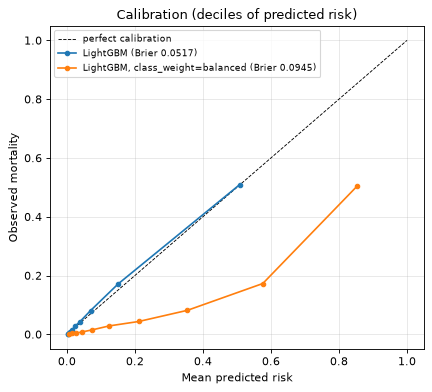

In [27]:
balanced_lightgbm = wu.make_lightgbm(**lgbm_params, class_weight="balanced")
run_cv("LightGBM, class_weight=balanced", balanced_lightgbm)

table = cv_table(["LightGBM", "LightGBM, class_weight=balanced"])
table["mean predicted risk"] = [oof_predictions[n].mean() for n in table.index]
table["observed mortality"] = y_dev.mean()
display(table)
wu.plot_calibration(y_dev, {name: oof_predictions[name] for name in table.index})
plt.show()

**Observations.**
* With `class_weight="balanced"`, the ranking quality is essentially unchanged (ROC-AUC 0.906 vs 0.908, PR-AUC slightly lower), but the **mean predicted risk jumps to 0.229 while the true mortality is 0.086**: the probabilities are inflated by a factor of ~2.7 and the calibration curve lies far below the diagonal.
* Without weights, the mean predicted risk (0.083) matches the observed mortality (0.086).
* **Decision:** no re-weighting. We keep honest probabilities and deal with the imbalance by moving the decision threshold, which gives the same trade-off between recall and alerts without destroying calibration.

# 4. Evaluation on unseen hospitals

The selected models are now re-trained on the **whole development set** and evaluated **once** on the test hospitals. Nothing below was used to choose a model or a hyperparameter.

## 4.1 Choosing the decision threshold
**Clinical goal (our assumption):** the model is used as a *screening* tool to flag patients for closer review by the ICU team. Missing a patient who will die is worse than reviewing a patient who survives, so we require the alert to **catch at least 80% of deaths** (recall ≥ 0.80), and among the thresholds that achieve this we choose the **highest**, which gives the fewest alerts.

The threshold is chosen on the **out-of-fold predictions of the development set** (Section 3), never on the test set. For comparison we also compute the threshold that maximises F1.

In [28]:
final_models = {
    "Dummy (prior)": (DummyClassifier(strategy="prior"), X_dev, X_test),
    "Logistic regression": (logistic_regression, X_dev, X_test),
    "Random forest": (random_forest, X_dev, X_test),
    "LightGBM": (lightgbm_model, X_dev, X_test),
    "LightGBM + APACHE features": (lightgbm_model, X_dev_apache, X_test_apache),
}
test_predictions, thresholds, fitted = {}, {}, {}
for name, (model, train_features, test_features) in final_models.items():
    fitted[name] = sklearn.clone(model).fit(train_features, y_dev)
    test_predictions[name] = fitted[name].predict_proba(test_features)[:, 1]
    if name != "Dummy (prior)":
        thresholds[name] = wu.threshold_for_recall(y_dev, oof_predictions[name], TARGET_RECALL)

f1_threshold = wu.threshold_for_best_f1(y_dev, oof_predictions["LightGBM"])
print(f"LightGBM threshold for recall >= {TARGET_RECALL:.0%} (chosen on dev OOF): {thresholds['LightGBM']:.3f}")
print(f"LightGBM threshold maximising F1 (for comparison):           {f1_threshold:.3f}")

LightGBM threshold for recall >= 80% (chosen on dev OOF): 0.089
LightGBM threshold maximising F1 (for comparison):           0.265


## 4.2 Test-set results

In [29]:
test_table = pd.DataFrame({
    name: wu.evaluate_predictions(y_test, proba, thresholds.get(name, 0.5))
    for name, proba in test_predictions.items()}).T
test_table.insert(0, "threshold", pd.Series(thresholds))
display(test_table)

for metric_name, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score)]:
    low, high = wu.bootstrap_metric(y_test, test_predictions["LightGBM"], metric)
    print(f"LightGBM test {metric_name}: 95% bootstrap interval [{low:.4f}, {high:.4f}]")

,threshold,ROC-AUC,PR-AUC,Brier,recall,precision,F1,specificity,alert rate
Dummy (prior),NaN,0.500,0.087,0.079,0.000,0.000,0.000,1.000,0.000
Logistic regression,0.085,0.885,0.534,0.056,0.815,0.289,0.426,0.810,0.244
Random forest,0.112,0.878,0.530,0.057,0.797,0.267,0.400,0.793,0.258
LightGBM,0.089,0.900,0.585,0.052,0.800,0.310,0.446,0.831,0.224
LightGBM + APACHE features,0.088,0.898,0.581,0.053,0.791,0.306,0.441,0.829,0.224


LightGBM test ROC-AUC: 95% bootstrap interval [0.8924, 0.9079]


LightGBM test PR-AUC: 95% bootstrap interval [0.5618, 0.6101]


**Observations (34 hospitals never seen during development).**
* **LightGBM**: ROC-AUC **0.900** (95% bootstrap interval 0.892–0.908), PR-AUC **0.585** (0.562–0.610), Brier 0.052. It remains the best model on every metric. The ranking is the same as in cross-validation: LightGBM > logistic regression (0.885) > random forest (0.878).
* The test ROC-AUC is slightly below the CV estimate (0.908). This difference is within the fold-to-fold variability: with only 34 test hospitals, the composition of the test set matters.
* The **threshold chosen on development data transfers to new hospitals**: it was set to reach 80% recall on the development set, and it gives exactly **80.0% recall** on the test hospitals. The price is an alert for 22.4% of patients, with precision 0.31: about **1 in 3 alerts is a patient who will die**, against about 1 in 11.5 if patients were flagged at random.
* Adding the APACHE predictions as features does not help on the test set either (0.898).
* **Comparison with the SOTA:** the leaderboard winners reach ≈ 0.915 on Kaggle's private test set, with large ensembles. Our single LightGBM is about 0.01 below, but **the two numbers are not computed on the same patients**, and ours is measured on hospitals that are completely absent from training. For reference, the 14th-place team reported a best single LightGBM of 0.9097 in (non-grouped) CV with ~700–2,000 engineered features; our grouped CV estimate is 0.908 with 179 features.

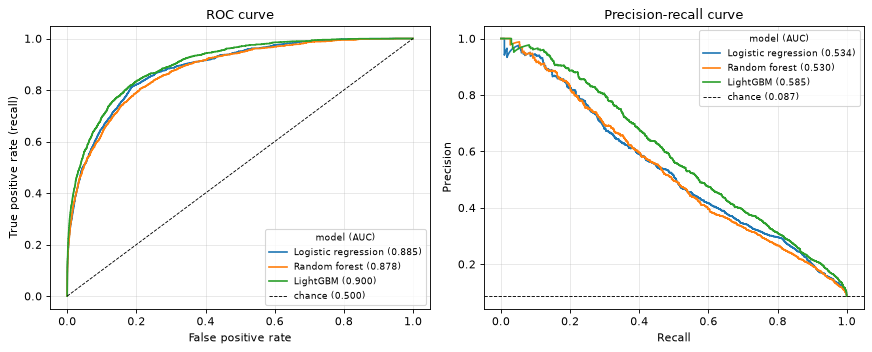

In [30]:
wu.plot_roc_and_pr(y_test, {name: test_predictions[name]
                            for name in ["Logistic regression", "Random forest", "LightGBM"]},
                   prevalence=y_test.mean())
plt.show()

## 4.3 Confusion matrices

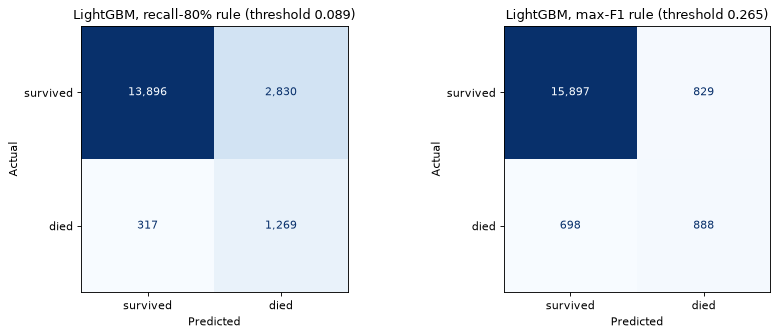

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (label, threshold) in zip(axes, [(f"recall-{TARGET_RECALL:.0%} rule", thresholds["LightGBM"]),
                                         ("max-F1 rule", f1_threshold)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions["LightGBM"] >= threshold, display_labels=["survived", "died"],
        values_format=",", colorbar=False, cmap="Blues", ax=ax)
    ax.set(title=f"LightGBM, {label} (threshold {threshold:.3f})",
           xlabel="Predicted", ylabel="Actual")
    ax.grid(False)
fig.tight_layout()
plt.show()

**Observations.** With our **recall-80% rule** (left), 1,269 of the 1,586 test deaths are flagged and 317 are missed, at the cost of 2,830 false alarms (about 2.2 false alarms per detected death). The **max-F1 rule** (right) gives far fewer false alarms (829) but misses 698 deaths (44%). F1 weights precision and recall equally, which does not reflect the clinical costs of a screening tool, where a missed death is much worse than a review of a patient who survives. The "right" threshold is a clinical choice, not a statistical one; our code makes it a single parameter (`TARGET_RECALL`).

## 4.4 Calibration
A calibration curve groups patients into ten bins of predicted risk and plots the observed death rate in each bin. Points on the diagonal mean the probabilities can be read literally. The Brier score is the mean squared error between the probability and the 0/1 outcome (lower is better).

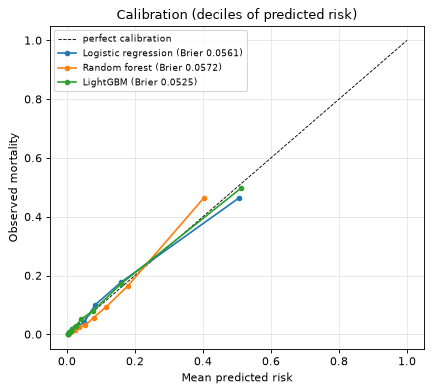

In [32]:
wu.plot_calibration(y_test, {name: test_predictions[name]
                             for name in ["Logistic regression", "Random forest", "LightGBM"]})
plt.show()

**Observations.** All three models are close to the diagonal, so their probabilities can be read literally. LightGBM has the best Brier score (0.0525). The random forest is slightly **under-confident at high risk** (in its top decile it predicts about 0.40 on average while about 0.46 die), a known effect of averaging many trees, which pulls probabilities towards the middle. Since LightGBM is already well calibrated on unseen hospitals, we did not add a post-hoc calibration step (Platt scaling or isotonic regression). It would be the first fix if a new hospital showed a calibration drift.

## 4.5 Head-to-head with APACHE IVa
APACHE IVa is only available for some patients, so the comparison is done **on the test patients that have an APACHE score**. The confidence interval of the **difference** in ROC-AUC is computed by bootstrapping the same resampled patients for both models (paired comparison).

The **decision curve** shows the *net benefit* of each strategy across thresholds: net benefit = (true alerts − false alerts × t/(1−t)) / n, where t/(1−t) is how many false alarms we accept per extra death detected. A model is useful at a threshold where it is above both "alert everyone" and "alert no one".

In [33]:
test_apache = X_test_apache["apache_4a_hospital_death_prob"].to_numpy()
has_score = ~np.isnan(test_apache)
y_sub = y_test[has_score]
head_to_head = {"APACHE IVa": test_apache[has_score],
                "LightGBM": test_predictions["LightGBM"][has_score],
                "LightGBM + APACHE features": test_predictions["LightGBM + APACHE features"][has_score]}
apache_threshold = wu.threshold_for_recall(y_dev[dev_has_apache], dev_apache[dev_has_apache], TARGET_RECALL)
sub_thresholds = {"APACHE IVa": apache_threshold, "LightGBM": thresholds["LightGBM"],
                  "LightGBM + APACHE features": thresholds["LightGBM + APACHE features"]}

print(f"Test patients with an APACHE score: {has_score.sum():,} / {len(y_test):,}")
display(pd.DataFrame({name: wu.evaluate_predictions(y_sub, proba, sub_thresholds[name])
                      for name, proba in head_to_head.items()}).T)

for metric_name, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score)]:
    low, high = wu.bootstrap_metric(y_sub, head_to_head["LightGBM"], metric, proba_b=head_to_head["APACHE IVa"])
    print(f"{metric_name} difference LightGBM - APACHE IVa: 95% interval [{low:+.4f}, {high:+.4f}]")

Test patients with an APACHE score: 15,817 / 18,312


,ROC-AUC,PR-AUC,Brier,recall,precision,F1,specificity,alert rate
APACHE IVa,0.862,0.444,0.064,0.821,0.229,0.358,0.735,0.314
LightGBM,0.903,0.599,0.052,0.797,0.315,0.452,0.834,0.221
LightGBM + APACHE features,0.903,0.599,0.052,0.799,0.310,0.447,0.830,0.225


ROC-AUC difference LightGBM - APACHE IVa: 95% interval [+0.0346, +0.0482]


PR-AUC difference LightGBM - APACHE IVa: 95% interval [+0.1340, +0.1763]


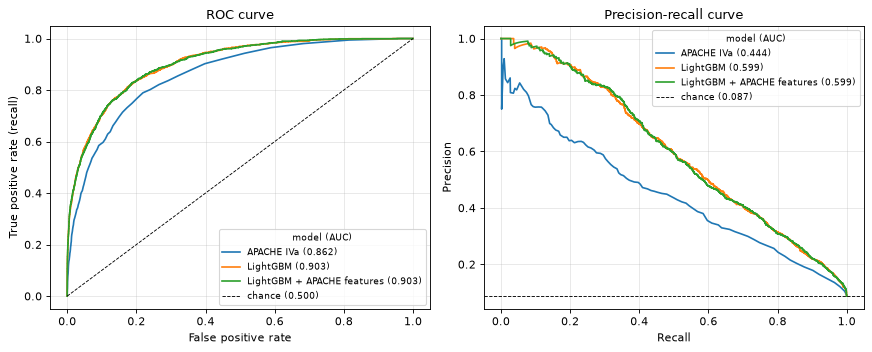

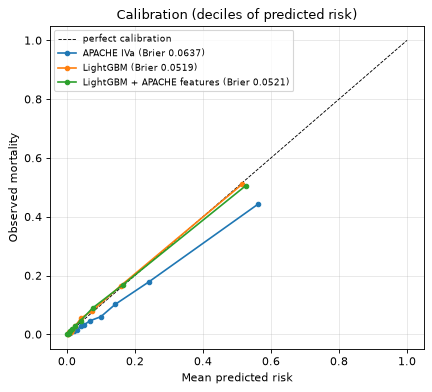

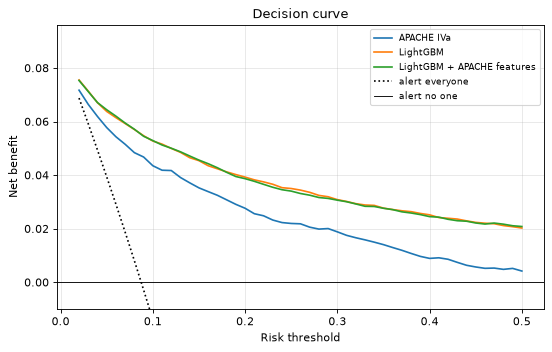

In [34]:
wu.plot_roc_and_pr(y_sub, head_to_head, prevalence=y_sub.mean())
plt.show()
wu.plot_calibration(y_sub, head_to_head)
wu.plot_decision_curve(y_sub, head_to_head, thresholds=np.linspace(0.02, 0.5, 49))
plt.show()

**Observations (15,817 test patients with an APACHE score).**
* **Discrimination:** LightGBM ROC-AUC 0.903 vs APACHE IVa 0.862. The 95% paired-bootstrap interval of the difference is **[+0.035, +0.048]** for ROC-AUC and **[+0.134, +0.176]** for PR-AUC (0.599 vs 0.444). The improvement is clearly larger than the statistical uncertainty.
* **Same clinical goal, fewer alerts:** with the threshold of each method set for 80% recall on development data, APACHE must alert **31.4%** of patients (precision 0.23) while LightGBM alerts **22.1%** (precision 0.31) for the same recall. That is about 9 fewer alerts per 100 admissions.
* **Calibration:** APACHE IVa systematically **over-estimates** risk in this population (its points lie under the diagonal; Brier 0.064 vs 0.052). A fixed score developed on another population and period typically drifts like this; a model trained on recent local data does not.
* **Decision curve:** LightGBM has a higher net benefit than APACHE at every threshold from 2% to 50%, and both are better than "alert everyone" or "alert no one" over the useful range. Adding APACHE to LightGBM changes nothing.

## 4.6 Feature importance and SHAP
LightGBM's built-in importance ("gain") tells us which features the trees used most, but not in which direction they push the prediction. **SHAP values** decompose each individual prediction (in log-odds) into a contribution per feature, so that *base value + sum of contributions = model output*. Averaging their absolute values gives a global importance; the beeswarm plot shows the direction (colour = feature value).

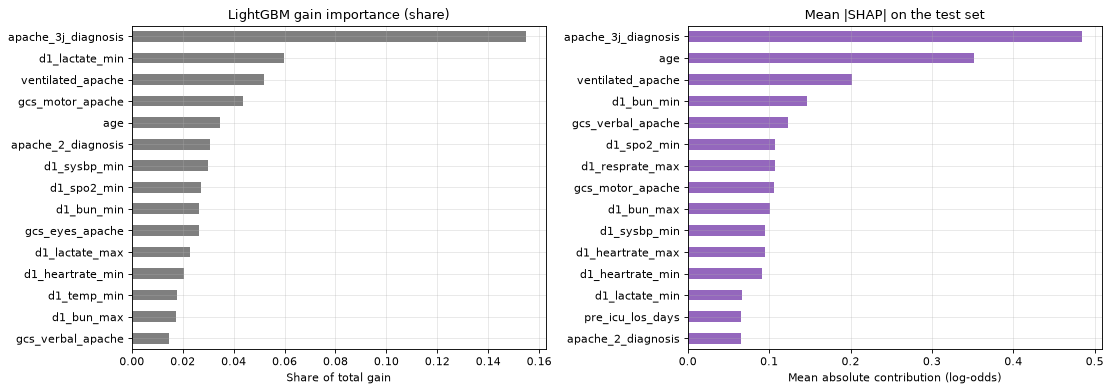

In [35]:
final_lightgbm = fitted["LightGBM"]
gain = pd.Series(final_lightgbm.booster_.feature_importance("gain"), index=X_dev.columns)

explainer = shap.TreeExplainer(final_lightgbm)
shap_values = explainer(X_test)  # one row of contributions per test patient (log-odds)
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
(gain / gain.sum()).nlargest(15)[::-1].plot.barh(ax=axes[0], color="tab:gray")
axes[0].set(title="LightGBM gain importance (share)", xlabel="Share of total gain")
mean_abs_shap.nlargest(15)[::-1].plot.barh(ax=axes[1], color="tab:purple")
axes[1].set(title="Mean |SHAP| on the test set", xlabel="Mean absolute contribution (log-odds)")
fig.tight_layout()
plt.show()

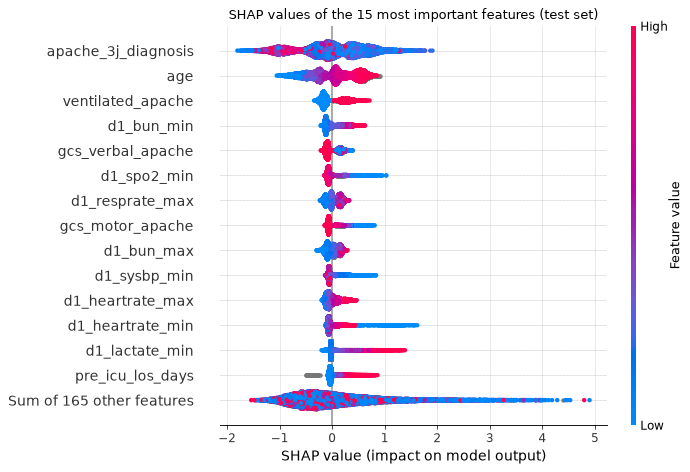

In [36]:
shap.plots.beeswarm(shap_values, max_display=15, show=False, plot_size=(9, 6))
plt.title("SHAP values of the 15 most important features (test set)")
plt.tight_layout()
plt.show()

**How to read the beeswarm.** Each dot is a test patient; its position is the SHAP value (positive = pushes towards death, in log-odds), and its colour is the feature value (red = high, blue = low). Grey dots are missing values; `apache_3j_diagnosis` is categorical, so its colour has no meaning (only the spread matters).

**Observations.**
* The **admission diagnosis group** has the largest effect: depending on the diagnosis, it moves the log-odds by up to about 2 in either direction. The same physiological values mean different risks for, say, a planned cardiac surgery and a septic shock.
* The other top features are clinically sensible: **older age**, **mechanical ventilation** on day 1, high **urea (BUN)** (kidney failure), low **Glasgow Coma Scale** (verbal and motor, reduced consciousness), low **minimum oxygen saturation** and **blood pressure**, high **respiratory rate**, high **lactate**, and **long stays before ICU admission**. A very **low minimum heart rate** (blue dots on the right) strongly increases risk, consistent with bradycardia or cardiac arrest.
* The importance is spread out: the remaining 165 features together ("sum of other features") have a large effect. The prediction is not driven by one variable, which is also why the task needs a multivariate model.
* Caveats: SHAP explains **the model**, not causality, and correlated features share credit (Section 2.5).

## 4.7 Error analysis — which patients does the model get wrong?
We split the test patients into the four cells of the confusion matrix (at our recall-80% threshold) and compare their typical values for the most important features. **False negatives** (deaths the model missed) are the clinically costly errors.

In [37]:
predicted_alert = test_predictions["LightGBM"] >= thresholds["LightGBM"]
outcome = np.select(
    [predicted_alert & (y_test == 1), ~predicted_alert & (y_test == 1),
     predicted_alert & (y_test == 0), ~predicted_alert & (y_test == 0)],
    ["TP (death, alerted)", "FN (death, missed)", "FP (survived, alerted)", "TN (survived, no alert)"],
    default="")

top_features = mean_abs_shap.nlargest(8).index.tolist()
numeric_top = [f for f in top_features + ["age", "n_missing_values"] if f not in wu.categorical_columns(X_test)]
error_profile = X_test[list(dict.fromkeys(numeric_top))].groupby(outcome).median().T
error_profile.loc["patients"] = pd.Series(outcome).value_counts()
error_profile.loc["median predicted risk"] = pd.Series(test_predictions["LightGBM"]).groupby(outcome).median()
error_profile.loc["elective surgery (%)"] = X_test["elective_surgery"].groupby(outcome).mean() * 100
error_profile.loc["ventilated on day 1 (%)"] = X_test["ventilated_apache"].groupby(outcome).mean() * 100
error_profile.round(2)

,"FN (death, missed)","FP (survived, alerted)","TN (survived, no alert)","TP (death, alerted)"
age,68.00,72.00,63.00,71.00
ventilated_apache,0.00,1.00,0.00,1.00
d1_bun_min,20.00,32.00,16.00,32.00
gcs_verbal_apache,5.00,4.00,5.00,1.00
d1_spo2_min,92.00,91.00,93.00,89.00
d1_resprate_max,29.00,31.00,27.00,33.00
gcs_motor_apache,6.00,6.00,6.00,5.00
n_missing_values,65.00,55.00,67.00,50.00
patients,317.00,2830.00,13896.00,1269.00
median predicted risk,0.04,0.18,0.01,0.45


In [38]:
deaths = y_test == 1
missed_by_system = pd.crosstab(X_test["apache_3j_bodysystem"].to_numpy()[deaths], outcome[deaths],
                               rownames=["body system"], colnames=["outcome"], normalize="index")
missed_by_system["deaths"] = X_test["apache_3j_bodysystem"][deaths].value_counts()
missed_by_system.sort_values("FN (death, missed)", ascending=False).round(3)

outcome,"FN (death, missed)","TP (death, alerted)",deaths
body system,,,
Gynecological,1.000,0.000,1
Metabolic,0.640,0.360,25
Gastrointestinal,0.346,0.654,127
Neurological,0.304,0.696,181
Musculoskeletal/Skin,0.250,0.750,8
Trauma,0.250,0.750,20
Cardiovascular,0.193,0.807,441
Respiratory,0.185,0.815,248
Genitourinary,0.167,0.833,24


In [39]:
# Which features pushed the missed deaths towards "low risk"? Mean SHAP value (log-odds), FN vs TP.
shap_frame = pd.DataFrame(shap_values.values, columns=X_test.columns)
shap_by_outcome = shap_frame[deaths].groupby(outcome[deaths]).mean().T
shap_by_outcome["FN - TP"] = shap_by_outcome["FN (death, missed)"] - shap_by_outcome["TP (death, alerted)"]
shap_by_outcome.sort_values("FN - TP").head(10).round(3)

,"FN (death, missed)","TP (death, alerted)",FN - TP
apache_3j_diagnosis,0.046,0.513,-0.467
d1_lactate_min,-0.017,0.201,-0.218
ventilated_apache,-0.023,0.195,-0.218
gcs_motor_apache,0.007,0.153,-0.146
d1_sysbp_min,0.002,0.130,-0.128
d1_spo2_min,-0.000,0.125,-0.125
gcs_eyes_apache,-0.010,0.093,-0.104
d1_bun_min,0.021,0.123,-0.101
age,0.078,0.177,-0.099
d1_heartrate_min,0.004,0.097,-0.093


**Observations.**
* **Missed deaths (FN, 317 patients) look like survivors on day 1**: median predicted risk 0.04, only 34% ventilated (vs 73% for detected deaths), normal verbal GCS (5), lower urea, more elective surgery (9.8% vs 3.8%), and *more missing values* (65 vs 50), meaning the clinical team also ordered fewer tests. The SHAP comparison confirms it: for missed deaths, the diagnosis, lactate, ventilation and GCS contribute almost nothing towards death, while they push detected deaths strongly upwards. These patients were most likely **stable during the first 24 hours and deteriorated later**, or died for reasons not visible in first-day physiology. This is a **limit of the data, not of the model**: no model restricted to day-1 data can see a later complication.
* Missed deaths are concentrated in some diagnosis groups: **metabolic** (64% of 25 deaths missed), gastrointestinal (35%) and neurological (30%), while **sepsis** (11%), respiratory and cardiovascular deaths are well detected.
* **False alarms (FP, 2,830 patients)** are older (median 72) and 60% were ventilated: they were genuinely severely ill patients who survived, possibly *because* of their care. For a screening tool these alerts are acceptable, since these patients deserved attention anyway.

## 4.8 Does performance differ across subgroups?
For each subgroup with at least 20 deaths in the test set we report discrimination (ROC-AUC), the recall obtained with the *global* threshold, and calibration-in-the-large (mean predicted risk vs observed mortality). A fair model should have similar recall and calibration across groups.

In [40]:
age_band = pd.cut(X_test["age"], bins=[0, 45, 65, 80, 120], labels=["<45", "45-64", "65-79", "80+"],
                  right=False).astype(str).replace("nan", np.nan)
subgroups = {"age": age_band, "sex": X_test["gender"], "ethnicity": X_test["ethnicity"],
             "ICU type": X_test["icu_type"], "elective surgery": X_test["elective_surgery"].map({0: "no", 1: "yes"})}
subgroup_tables = pd.concat(
    {name: wu.subgroup_report(y_test, test_predictions["LightGBM"], thresholds["LightGBM"],
                              values.to_numpy())
     for name, values in subgroups.items()})
subgroup_tables

n  deaths  observed mortality  \
                 group                                                 
age              45-64              6052     419               0.069   
                 65-79              5919     561               0.095   
                 80+                2946     373               0.127   
                 <45                2510     103               0.041   
sex              M                  9810     807               0.082   
                 F                  8495     779               0.092   
ethnicity        Caucasian         13630    1185               0.087   
                 African American   2002     168               0.084   
                 Hispanic           1018      82               0.081   
                 Other/Unknown       827      73               0.088   
                 Asian               391      38               0.097   
                 Native American     216      23               0.106   
ICU type         Med-Surg ICU      11906    1101               0.092   
                 CTICU              1845      75               0.041   
                 Neuro ICU          1377     113               0.082   
                 CCU-CTICU           942      83               0.088   
                 Cardiac ICU         807      99               0.123   
                 MICU                670      69               0.103   
                 SICU                391      26               0.066   
                 CSICU               374      20               0.053   
elective surgery no                14820    1507               0.102   
                 yes                3492      79               0.023   

                                   mean predicted risk  ROC-AUC  recall  \
                 group                                                    
age              45-64                           0.066    0.922   0.788   
                 65-79                           0.098    0.889   0.807   
                 80+                             0.128    0.850   0.820   
                 <45                             0.037    0.940   0.660   
sex              M                               0.082    0.897   0.792   
                 F                               0.090    0.903   0.809   
ethnicity        Caucasian                       0.087    0.901   0.806   
                 African American                0.080    0.893   0.786   
                 Hispanic                        0.074    0.908   0.768   
                 Other/Unknown                   0.090    0.927   0.822   
                 Asian                           0.088    0.852   0.632   
                 Native American                 0.105    0.929   0.913   
ICU type         Med-Surg ICU                    0.094    0.902   0.827   
                 CTICU                           0.045    0.888   0.627   
                 Neuro ICU                       0.062    0.883   0.673   
                 CCU-CTICU                       0.089    0.881   0.735   
                 Cardiac ICU                     0.109    0.926   0.859   
                 MICU                            0.099    0.881   0.826   
                 SICU                            0.080    0.887   0.808   
                 CSICU                           0.034    0.935   0.550   
elective surgery no                              0.099    0.891   0.810   
                 yes                             0.030    0.903   0.608   

                                   alert rate  
                 group                         
age              45-64                  0.159  
                 65-79                  0.261  
                 80+                    0.352  
                 <45                    0.080  
sex              M                      0.216  
                 F                      0.233  
ethnicity        Caucasian              0.229  
                 African American       0.204  
                 Hispanic    

Test hospitals with >= 10 deaths: 19 / 34
       ROC-AUC  recall  observed mortality  mean predicted risk
count   19.000  19.000              19.000               19.000
mean     0.894   0.785               0.088                0.088
std      0.040   0.112               0.025                0.025
min      0.776   0.583               0.051                0.045
25%      0.895   0.710               0.070                0.071
50%      0.904   0.807               0.088                0.084
75%      0.911   0.876               0.100                0.104
max      0.946   0.964               0.144                0.154


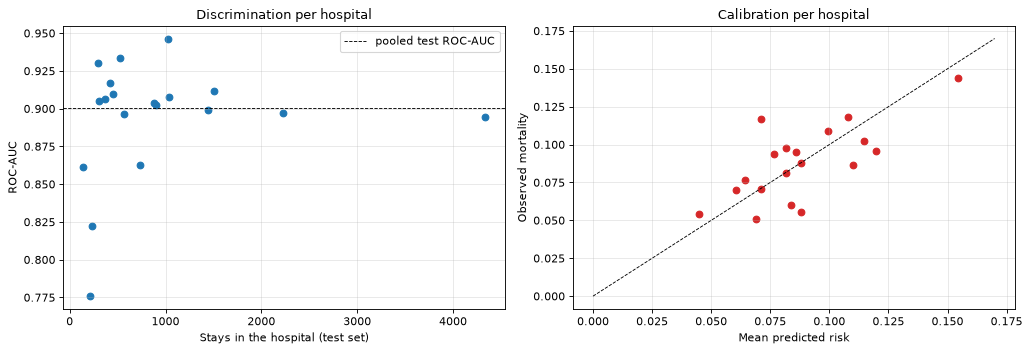

In [41]:
per_hospital = wu.subgroup_report(y_test, test_predictions["LightGBM"], thresholds["LightGBM"],
                                  groups_test, min_deaths=10)
print(f"Test hospitals with >= 10 deaths: {len(per_hospital)} / {len(set(groups_test))}")
print(per_hospital[["ROC-AUC", "recall", "observed mortality", "mean predicted risk"]].describe().round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(per_hospital["n"], per_hospital["ROC-AUC"], color="tab:blue")
axes[0].axhline(roc_auc_score(y_test, test_predictions["LightGBM"]), color="k", ls="--", lw=0.8,
                label="pooled test ROC-AUC")
axes[0].set(xlabel="Stays in the hospital (test set)", ylabel="ROC-AUC", title="Discrimination per hospital")
axes[0].legend()
axes[1].scatter(per_hospital["mean predicted risk"], per_hospital["observed mortality"], color="tab:red")
limit = per_hospital[["mean predicted risk", "observed mortality"]].to_numpy().max() * 1.1
axes[1].plot([0, limit], [0, limit], "k--", lw=0.8)
axes[1].set(xlabel="Mean predicted risk", ylabel="Observed mortality", title="Calibration per hospital")
fig.tight_layout()
plt.show()

**Observations.**
* **Age:** discrimination decreases with age (ROC-AUC 0.940 for < 45 years, 0.922 for 45–64, 0.889 for 65–79, 0.850 for 80+): among the very old, almost everyone is "at risk" and death is harder to separate. With the single global threshold, recall is only **0.66 for patients under 45** (their predicted risks are lower, so fewer cross the threshold) vs 0.82 for 80+. Calibration-in-the-large is good in every age band (e.g. 0.128 predicted vs 0.127 observed for 80+).
* **Sex:** no meaningful difference (F: ROC-AUC 0.903, recall 0.81; M: 0.897, 0.79).
* **Ethnicity:** similar for the large groups (Caucasian 0.901, African American 0.893, Hispanic 0.908). The Asian group has a lower AUC (0.852) and recall (0.63), but with only 38 deaths the uncertainty is large; we can neither confirm nor exclude a real gap.
* **ICU type and surgery:** recall is low in **low-mortality settings**: cardiac-surgery ICUs (CSICU 0.55, CTICU 0.63), Neuro ICU (0.67) and elective surgery patients (0.61), while ROC-AUC stays ≥ 0.88. The model still ranks patients correctly within these groups, but a single global threshold under-alerts where the baseline risk is low. A unit-specific threshold would fix this but raises its own questions (different rules for different patients), which should be discussed with clinicians.
* **Per hospital** (19 test hospitals with ≥ 10 deaths): median ROC-AUC 0.904, ranging from 0.776 to 0.946. The lowest values come from small hospitals (≈ 200 stays) where the estimate is noisy. Recall ranges from 0.58 to 0.96 and some hospitals are visibly mis-calibrated (right plot). **A local check, and if needed a recalibration, should precede any deployment in a new hospital.**

# 5. Conclusion

## What we did
We predicted in-hospital death from the first 24 hours of 91,713 ICU stays (WiDS Datathon 2020). Rather than optimising the leaderboard metric with large ensembles, we asked whether a model would be **trustworthy in a hospital it has never seen**. We therefore built a leakage-aware pipeline: hospital-grouped cross-validation and a test set of 34 unseen hospitals, identifiers excluded, APACHE IVa kept as an external benchmark, cleaning of inconsistent values, and missingness preserved as information. We compared a dummy baseline, logistic regression, a random forest and LightGBM, and then evaluated the best model as a clinical tool: decision threshold, calibration, decision curve, comparison with APACHE, SHAP explanations, error analysis and fairness across subgroups and hospitals.

## What worked
* **LightGBM** was the best model at every stage: grouped CV ROC-AUC 0.908, and on unseen hospitals **ROC-AUC 0.900 [0.892–0.908], PR-AUC 0.585**, with well-calibrated probabilities (Brier 0.052) and no post-hoc calibration.
* It **clearly beats the clinical APACHE IVa score** on the same patients (+0.035 to +0.048 ROC-AUC, +0.13 to +0.18 PR-AUC, 95% intervals). For the same goal of catching 80% of deaths, it alerts 22% of patients instead of 31%.
* The **recall-80% threshold chosen on development data held exactly on new hospitals** (80.0% recall).
* The controlled experiments justified our design choices: dropping APACHE costs nothing, hospital IDs only "help" under a misleading random split, missingness alone predicts death (AUC 0.765), and class re-weighting destroys calibration without improving ranking.

## What did not work, or remains a limitation
* The **random forest** did not beat logistic regression, and **adding APACHE** brought nothing.
* About **20% of deaths are missed by design** (our threshold), and these patients look stable on day 1. First-day data cannot predict later deterioration.
* Performance is **less good for the oldest patients**, and the global threshold **under-alerts in low-risk groups** (young patients, cardiac-surgery ICUs, elective surgery). Some groups (e.g. Asian patients, 38 deaths) are too small to conclude.
* Performance **varies between hospitals** (ROC-AUC 0.78–0.95), so the model needs a local check before use.
* Our score is **not comparable** with the Kaggle leaderboard (different test patients) and we stayed about 0.01 below the winners' numbers, a gap we accepted to keep a simple, explainable model.

## If we had more time
1. **Feature engineering with clinical meaning** (as in the top solutions): total GCS, shock index, first-hour vs first-day changes, organ-failure counts.
2. **Hospital-level robustness:** leave-one-hospital-out evaluation, and a simple recalibration procedure for a new hospital using a few weeks of its data.
3. **Subgroup-aware thresholds** discussed with clinicians, and confidence intervals for all subgroup metrics.
4. **More tuning** (Bayesian optimisation, early stopping) and a small ensemble of LightGBM and logistic regression, to quantify how much accuracy simplicity costs us.
5. **External validation** on another dataset (e.g. MIMIC or eICU on PhysioNet) and an analysis of time trends.

## References
* WiDS Datathon 2020 data: Kaggle <https://www.kaggle.com/competitions/widsdatathon2020/data>; PhysioNet: Lee, M., Raffa, J., Ghassemi, M., et al., *WiDS (Women in Data Science) Datathon 2020: ICU Mortality Prediction* (v1.0.0) <https://physionet.org/content/widsdatathon2020/1.0.0/>
* Kaggle leaderboard and solution write-ups: links in Section 1.5.
* Ren, N., Zhao, X., Zhang, X. (2022). Mortality prediction in ICU using a stacked ensemble model. *Computational and Mathematical Methods in Medicine*. doi:10.1155/2022/3938492
* Caires Silveira, E., et al. (2022). Prediction of hospital mortality in intensive care unit patients from clinical and laboratory data: a machine learning approach. *World Journal of Critical Care Medicine* 11(5), 317. doi:10.5492/wjccm.v11.i5.317
* Lundberg, S. M., Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). *NeurIPS*.
* Vickers, A. J., Elkin, E. B. (2006). Decision curve analysis: a novel method for evaluating prediction models. *Medical Decision Making* 26(6).